# 实验报告 02：NumPy、SciPy、Matplotlib 与 pandas 数据处理

姓名：石辉宇　　学号：20244081119

In [3]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

STUDENT_ID = 20244081119
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] py_lrCode
[学号]       20244081119
[机器指纹] b5c030feb0674ca8
[RUN_ID]   20244081119-b5c030feb0674ca8


## 实验 1：NumPy 数组、数据类型与索引

In [2]:
#1.1
a = np.array([1, 2, 3])
b = np.array([1.2, 2.5, 3.8])
c = np.array([True, False, True])

for x in [a, b, c]:
    print(x)
    print("dtype:", x.dtype, "shape:", x.shape, "ndim:", x.ndim)
    # 1.1、 NumPy 数组的数据类型与 Python 列表的差别?
    # NumPy数组里的元素一般是同一种类型
    # 而 Python 列表可以同时放不同类型的数据

[1 2 3]
dtype: int64 shape: (3,) ndim: 1
[1.2 2.5 3.8]
dtype: float64 shape: (3,) ndim: 1
[ True False  True]
dtype: bool shape: (3,) ndim: 1


### 1.1 结果说明

三个数组的 `shape` 都是 `(3,)`，`ndim` 都是 1，说明它们都是含 3 个元素的一维数组。不同之处是数据类型分别为 `int64`、`float64` 和 `bool`，可见 NumPy 会根据元素确定数组的数据类型。

In [3]:
# 1.2
arr = np.arange(12)
arr1 = arr.reshape(3, 4)
arr2 = arr.reshape(2, 3, 2)
print(arr)
print(arr1)
print(arr2)
#1.2、说明改变形状时元素总数必须满⾜什么条件？ 改变形状前后元素个数不能变


[ 0  1  2  3  4  5  6  7  8  9 10 11]
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


**1.2 结果分析：** 原数组有 12 个元素，变成 `(3, 4)` 和 `(2, 3, 2)` 后元素的排列顺序没有改变，只是观察数据的维度不同。两个新形状的维度乘积都是 12，所以 `reshape` 没有增加或删除元素。

In [4]:
#1.3
row2 = arr1[1, :]
col1_3 = arr1[:, :3]
greater6 = arr1[arr1 > 6]

print("第2行：", row2, "形状：", row2.shape)
print("第1~3列：\n", col1_3, "形状：", col1_3.shape)
print("大于6：", greater6, "形状：", greater6.shape)

第2行： [4 5 6 7] 形状： (4,)
第1~3列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] 形状： (3, 3)
大于6： [ 7  8  9 10 11] 形状： (5,)


In [5]:
#1.4
n = np.arange(10)
print(n[(n < 2) | (n > 7)])
print(n[(n > 3) & (n < 7)])

[0 1 8 9]
[4 5 6]


In [6]:
#1.5
m1 = np.array([[1, 2], [3, 4]])
m2 = np.array([[5, 6], [7, 8]])
print("*：", m1 * m2)
print("multiply：", np.multiply(m1, m2))
print("@ ：", m1 @ m2)
print("matmul：", np.matmul(m1, m2))
#1.5、说明逐元素乘法与矩阵乘法的区别？
# `*` 和 `multiply` 是对应位置相乘，
# `@` 和 `matmul` 是按矩阵乘法规则计算。

*： [[ 5 12]
 [21 32]]
multiply： [[ 5 12]
 [21 32]]
@ ： [[19 22]
 [43 50]]
matmul： [[19 22]
 [43 50]]


### 实验 1 其余结果说明

- 1.3 中第 2 行得到 `[4, 5, 6, 7]`，形状为 `(4,)`；取前三列后仍有 3 行，所以形状是 `(3, 3)`。布尔索引选出的 5 个数会组成新的一维数组。
- 1.4 的两个结果分别是 `[0, 1, 8, 9]` 和 `[4, 5, 6]`，说明括号中的两个条件分别通过 `|` 和 `&` 正确组合。
- 1.5 中 `*` 与 `multiply` 的结果相同，都是对应位置相乘；`@` 与 `matmul` 的结果也相同，但它们计算的是矩阵行与列的乘积，所以结果与前两种方法不同。

## 实验 2：随机抽样、统计与缺失值

In [7]:
#2.1
# default_rng中传入固定的种子，这样重新运行时得到的随机数相同
rng = np.random.default_rng(20244081119)
scores = rng.normal(70, 10, 1000)
# clip把小于0的值改成0，大于100的值改成100
scores = np.clip(scores, 0, 100)

print("样本数：", len(scores))
print("最小值：", scores.min())
print("最大值：", scores.max())
print("均值：", scores.mean())
print("标准差：", scores.std())
print("极差：", np.ptp(scores))

样本数： 1000
最小值： 39.98434167412377
最大值： 100.0
均值： 70.28933932793758
标准差： 10.121246022115088
极差： 60.01565832587623


In [8]:
# 2.2
numbers = np.arange(1, 11)
# replace=False表示抽到的数不会再放回去
normal_choice = rng.choice(numbers, 5, replace=False)
# 每个数除以总和后就得到对应的抽样概率，数越大概率越大
p = numbers / numbers.sum()
weighted_choice = rng.choice(numbers, 5, replace=False, p=p)
print("均匀抽样：", normal_choice)
print("加权抽样：", weighted_choice)

均匀抽样： [ 7  5 10  1  2]
加权抽样： [10  7  3  6  8]


In [9]:
#2.3
x = np.arange(1, 11)
print("原数组：", x)
y = rng.permutation(x)
print("permutation结果：", y)
print("原数组仍为：", x)

z = np.arange(1, 11)
print("shuffle前：", z)
rng.shuffle(z)
print("shuffle后：", z)
# 2.3、两种随机排列有什么区别？
# permutation产生一个新的数组，所以x没有改变
# shuffle是在原数组上操作，所以z本身被打乱了

原数组： [ 1  2  3  4  5  6  7  8  9 10]
permutation结果： [ 9 10  8  4  5  6  3  7  2  1]
原数组仍为： [ 1  2  3  4  5  6  7  8  9 10]
shuffle前： [ 1  2  3  4  5  6  7  8  9 10]
shuffle后： [ 9  5  8  1  7  2 10  4  3  6]


### 2.1～2.3 结果分析

模拟成绩的均值为 70.289，标准差为 10.121，与生成数据时设定的均值 70、标准差 10 很接近。最大值正好是 100，说明原始随机数据中有超过 100 的值被 `clip` 截断。

均匀抽样和加权抽样在固定种子下得到了不同结果。加权抽样中较大的整数概率更高，但一次抽样结果不能单独证明分布规律。随机排列的输出还说明：`permutation` 之后原数组没有变化，而 `shuffle` 之后原数组本身已经被打乱。

In [10]:
# 2.4
scores_nan = scores.copy()
# 第10、20、30个值的下标分别是9、19、29
scores_nan[[9, 19, 29]] = np.nan
print("普通均值：", np.mean(scores_nan))
print("忽略缺失值的均值：", np.nanmean(scores_nan))
print("缺失值个数：", np.isnan(scores_nan).sum())
# 2.4、nan对普通统计函数有什么影响？
# mean遇到nan后结果也是nan，nanmean会先跳过缺失值再计算

#2.5
# DataFrame只保存在变量中，没有写入磁盘，后面实验4可以继续使用
score_df = pd.DataFrame({
    "序号": np.arange(1, 1001),
    "成绩": scores_nan
})
score_df.head(12)

普通均值： nan
忽略缺失值的均值： 70.28808316633135
缺失值个数： 3


,序号,成绩
0,1,83.897647
1,2,71.311797
2,3,79.450799
3,4,63.373187
4,5,78.488810
5,6,61.690458
6,7,55.098167
7,8,68.154237
8,9,55.301172
9,10,NaN


**2.4～2.5 结果说明：** 设置了 3 个缺失值后，普通均值变成 `nan`，而 `nanmean` 忽略缺失值后得到 70.288，与原均值 70.289 几乎相同。表格中序号 10 的成绩显示为 `NaN`，说明缺失值及其对应序号已经正确保存到内存中的 DataFrame。

## 实验 3：SciPy 数值计算与 Matplotlib 可视化

In [11]:
#3.1
from scipy import linalg, optimize, stats

# 把方程组左边的系数写成矩阵A，右边写成b
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
answer = linalg.solve(A, b)
print("方程组的解：", answer)
print("代入结果：", A @ answer)
# allclose适合判断浮点数计算结果是否近似相等
print("验证：", np.allclose(A @ answer, b))

方程组的解： [2. 3.]
代入结果： [9. 8.]
验证： True


In [12]:
# 3.2
def fun(x):
    return x ** 2 - 2

# 初始值1靠近正根，-1靠近负根
r1 = optimize.root(fun, 1)
r2 = optimize.root(fun, -1)
print("正根是否成功：", r1.success, "正根：", r1.x[0], "函数值：", fun(r1.x[0]))
print("负根是否成功：", r2.success, "负根：", r2.x[0], "函数值：", fun(r2.x[0]))
# 两个函数值都非常接近0，说明求出的结果确实是方程的根

正根是否成功： True 正根： 1.4142135623730947 函数值： -8.881784197001252e-16
负根是否成功： True 负根： -1.4142135623730947 函数值： -8.881784197001252e-16


In [13]:
#3.3
def f(x):
    return x[0] ** 2 + x[0] + 2

result = optimize.minimize(f, [0])
print("极小点：", result.x[0])
print("最小值：", result.fun)
print("解析结果：x=-0.5，f(x)=1.75")
# 3.3、与解析结果比较
# 数值结果和解析结果很接近，出现很小的误差是浮点数计算造成的

极小点： -0.5000000064345924
最小值： 1.75
解析结果：x=-0.5，f(x)=1.75


In [14]:
# 3.4
rng2 = np.random.default_rng(20244081119)
sample1 = rng2.normal(0, 1, 100)
sample2 = rng2.normal(1, 1, 100)
# ttest_ind用来检验两个独立样本的均值是否有明显差异
t, p_value = stats.ttest_ind(sample1, sample2)
print("t统计量：", t)
print("p值：", p_value)
if p_value < 0.05:
    print("p<0.05，拒绝原假设，两组均值有显著差异")
else:
    print("p>=0.05，不能拒绝原假设")
# 判断时把p值和题目给出的显著性水平0.05比较

t统计量： -8.869255278554645
p值： 4.339427004879723e-16
p<0.05，拒绝原假设，两组均值有显著差异


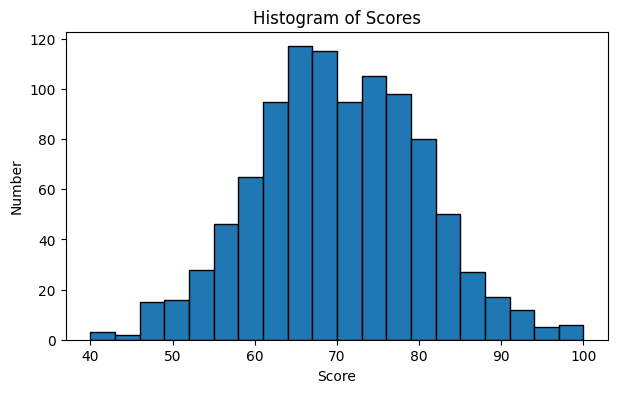

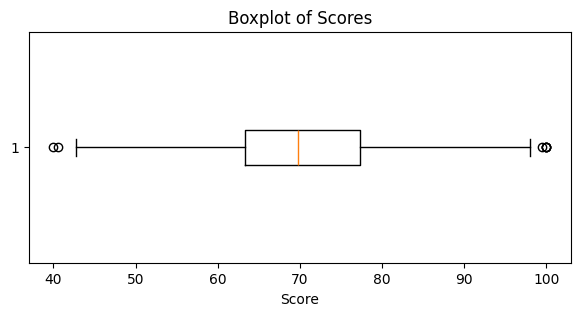

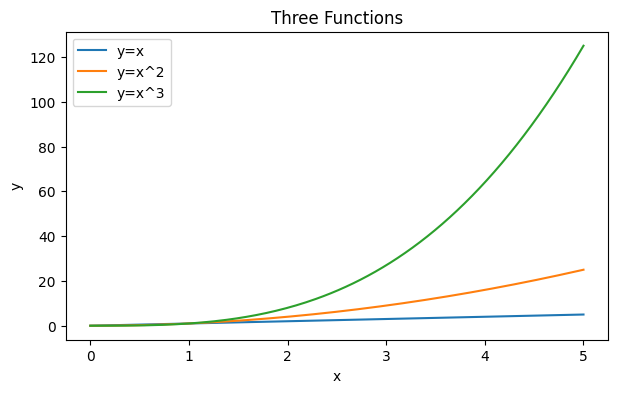

In [15]:
#3.5
# dropna先去掉缺失成绩，避免nan影响画图
valid_scores = score_df["成绩"].dropna()

# 直方图适合观察成绩大致集中在哪些区间
plt.figure(figsize=(7, 4))
plt.hist(valid_scores, bins=20, edgecolor="black")
plt.title("Histogram of Scores")
plt.xlabel("Score")
plt.ylabel("Number")
plt.show()

# 箱线图可以较直观地看到中位数、四分位数和离群值
plt.figure(figsize=(7, 3))
plt.boxplot(valid_scores, vert=False)
plt.title("Boxplot of Scores")
plt.xlabel("Score")
plt.show()

# linspace在0到5之间取200个点，点多一些时曲线看起来更平滑
x = np.linspace(0, 5, 200)
plt.figure(figsize=(7, 4))
plt.plot(x, x, label="y=x")
plt.plot(x, x ** 2, label="y=x^2")
plt.plot(x, x ** 3, label="y=x^3")
plt.title("Three Functions")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

### 实验 3 结果分析

方程组求得 $x=2$、$y=3$，代回后得到 `[9, 8]`，且验证结果为 `True`。方程的两个根约为 $\pm1.4142$，代入后的函数值约为 $-8.88\times10^{-16}$，这个很小的非零值来自浮点数误差，可以认为接近 0。

最优化得到的极小点为 -0.500000006，函数值为 1.75，与解析结果 $x=-0.5$、$f(x)=1.75$ 一致。t 检验得到 $t=-8.869$、$p=4.34\times10^{-16}$，p 值远小于 0.05，因此拒绝两组总体均值相等的原假设。

从直方图可以看到成绩主要集中在 70 分附近，箱线图则更方便观察中位数、四分位范围和极端值。最后一张图中，随着 $x$ 增大，$x^3$ 增长最快，$x^2$ 次之，$x$ 增长最慢。

## 实验 4：pandas Series、DataFrame 与内存中的 CSV 读写

In [16]:
#4.1
# 实验2中建立的表格直接保存在内存中
print(score_df.head())

records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82]
}

# set_index把Name列变成行索引，后面可以直接用姓名查找
df = pd.DataFrame(records).set_index("Name")
subjects = ["Math", "English", "Python"]
df["Total"] = df[subjects].sum(axis=1)
df["Average"] = df[subjects].mean(axis=1)
print("行索引：", df.index)
print("列名：", df.columns)
print(df.head(3))
# describe可以一次看到数量、均值、标准差、最大最小值等信息
print(df.describe())

   序号         成绩
0   1  83.897647
1   2  71.311797
2   3  79.450799
3   4  63.373187
4   5  78.488810
行索引： Index(['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank'], dtype='object', name='Name')
列名： Index(['Group', 'Math', 'English', 'Python', 'Total', 'Average'], dtype='object')
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.

In [17]:
# 4.2
# loc按行索引的名字读取，iloc按行的位置读取，Carol位于第3行所以位置是2
print("loc读取Carol：")
print(df.loc["Carol"])
print("iloc读取Carol：")
print(df.iloc[2])
print("平均分不低于80：")
print(df[df["Average"] >= 80])

loc读取Carol：
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
iloc读取Carol：
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
平均分不低于80：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [18]:
#4.3
# axis=0是每一列向下计算，所以得到每科平均分
print("每科平均分：")
print(df[subjects].mean(axis=0))
# axis=1是每一行横向计算，所以得到每个学生的平均分
print("每名学生三科平均分：")
print(df[subjects].mean(axis=1))

每科平均分：
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64
每名学生三科平均分：
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [19]:
# 4.4
# apply让max依次作用在每一行，得到每人的三科最高分
df["Highest"] = df[subjects].apply(max, axis=1)
print(df[["Highest"]])
# agg可以一次使用多个统计函数
print(df[subjects].agg(["min", "mean", "max"]))
# ascending=False表示分数越高，名次数字越小
df["Python排名"] = df["Python"].rank(ascending=False)
print(df[["Python", "Python排名"]])

       Highest
Name          
Alice       95
Bob         80
Carol       91
David       73
Eva         92
Frank       84
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000
       Python  Python排名
Name                   
Alice      95       1.0
Bob        80       5.0
Carol      89       2.0
David      70       6.0
Eva        86       3.0
Frank      82       4.0


In [20]:
#4.5
grouped = df.groupby("Group")
print("每组人数：")
print(grouped.size())
print("每组三科平均分：")
print(grouped[subjects].mean())
# transform的结果和原表行数相同，因此可以直接作为新的一列加回去
df["组内Python平均分"] = grouped["Python"].transform("mean")
print(df[["Group", "Python", "组内Python平均分"]])

每组人数：
Group
A    3
B    3
dtype: int64
每组三科平均分：
            Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333
      Group  Python  组内Python平均分
Name                            
Alice     A      95    87.000000
Bob       A      80    87.000000
Carol     B      89    80.333333
David     B      70    80.333333
Eva       A      86    87.000000
Frank     B      82    80.333333


In [21]:
# 4.6
# filter判断的是整个小组，满足条件时保留这个组里的所有学生
kept = grouped.filter(lambda x: x["Python"].mean() >= 80)
print("保留的组：", kept["Group"].unique())
print("保留的学生：", kept.index.tolist())
print(kept)

保留的组： ['A' 'B']
保留的学生： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
      Group  Math  English  Python  Total    Average  Highest  Python排名  \
Name                                                                      
Alice     A    88       90      95    273  91.000000       95       1.0   
Bob       A    72       68      80    220  73.333333       80       5.0   
Carol     B    91       85      89    265  88.333333       91       2.0   
David     B    65       73      70    208  69.333333       73       6.0   
Eva       A    79       92      86    257  85.666667       92       3.0   
Frank     B    84       77      82    243  81.000000       84       4.0   

       组内Python平均分  
Name                
Alice    87.000000  
Bob      87.000000  
Carol    80.333333  
David    80.333333  
Eva      87.000000  
Frank    80.333333  


In [22]:
#4.7
cov_result = df[subjects].cov()
corr_result = df[subjects].corr()
print("协方差矩阵：")
print(cov_result)
print("相关系数矩阵：")
print(corr_result)
print("Math和English的协方差：", cov_result.loc["Math", "English"])
print("Math和English的相关系数：", corr_result.loc["Math", "English"])
# 4.7、协方差符号与相关系数大小表示什么？
# 协方差为正表示两科成绩大致同向变化，为负表示反向变化
# 相关系数绝对值越接近1，线性关系越明显；越接近0，线性关系越弱

协方差矩阵：
              Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667
相关系数矩阵：
             Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000
Math和English的协方差： 62.56666666666668
Math和English的相关系数： 0.6535293080615485


### 实验 4 结果分析

三科总体平均分中 Python 最高，为 83.67；学生平均分不低于 80 的有 Alice、Carol、Eva 和 Frank。`loc` 与 `iloc` 得到的 Carol 记录完全相同，说明按标签和按位置都找到了同一行。

Python 排名中 Alice 第 1、Carol 第 2。A、B 两组各有 3 人，Python 平均分分别为 87.00 和 80.33，都不低于 80，因此 `filter` 最后保留了两个组和全部 6 名学生。

Math 与 English 的协方差为 62.57，是正数，表示两科成绩大体同向变化；相关系数约为 0.654，说明两科之间存在中等程度的正线性关系。三组相关系数都为正，其中 Math 与 Python 的相关系数 0.885 最大，线性关系最明显。